<div style="background: #444b52; padding: 20px; border-top-left-radius: 20px; border-top-right-radius: 20px;"><h1 style="color: White">Рекомендательные системы фильма</h1></div>
<img src='poster.jpg'></img>

<div style="padding: 20px;"><a>Импорт данных: </a>
    <a href="https://www.kaggle.com/code/prashant111/recommender-systems-in-python/input">Ссылка - kaggle</a>
</div>

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

**Загрузка данных**

In [8]:
movies=pd.read_csv("movies.csv")
rating=pd.read_csv("ratings.csv")
users = pd.read_csv("Users_new3.csv", sep=";", usecols=["userId", "Location", "Age"])

C:\Users\Айдар Юсупов\AppData\Local\Temp\ipykernel_30504\1248646775.py:3: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  users = pd.read_csv("Users_new3.csv", sep=";", usecols=["userId", "Location", "Age"])


In [106]:
result_name = df[df["title"].str.contains("Terminator", case=False, na=False)]
result_name

,userId,movieId,rating,timestamp,title
24,1,589,3.5,1217896078,Terminator 2 Judgment Day 1991
203,3,589,3.0,841483584,Terminator 2 Judgment Day 1991
489,7,589,4.5,1322065131,Terminator 2 Judgment Day 1991
511,7,1240,5.0,1322062949,Terminator The 1984
619,7,68791,3.5,1322058563,Terminator Salvation 2009
...,...,...,...,...,...
99379,666,589,4.0,1021280350,Terminator 2 Judgment Day 1991
99908,668,589,4.0,1057262140,Terminator 2 Judgment Day 1991
100178,668,1240,3.0,1025856721,Terminator The 1984
102098,668,6537,2.5,1059006758,Terminator 3 Rise of the Machines 2003


In [9]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [10]:
movies.tail()

,movieId,title,genres
10324,146684,Cosmic Scrat-tastrophe (2015),Animation|Children|Comedy
10325,146878,Le Grand Restaurant (1966),Comedy
10326,148238,A Very Murray Christmas (2015),Comedy
10327,148626,The Big Short (2015),Drama
10328,149532,Marco Polo: One Hundred Eyes (2015),(no genres listed)


In [11]:
rating.head()

,userId,movieId,rating,timestamp
0,1,16,4.0,1217897793
1,1,24,1.5,1217895807
2,1,32,4.0,1217896246
3,1,47,4.0,1217896556
4,1,50,4.0,1217896523


In [12]:
rating.tail()

,userId,movieId,rating,timestamp
105334,668,142488,4.0,1451535844
105335,668,142507,3.5,1451535889
105336,668,143385,4.0,1446388585
105337,668,144976,2.5,1448656898
105338,668,148626,4.5,1451148148


In [13]:
users.head()

,userId,Location,Age
0,1.0,"nyc, new york, usa",NaN
1,2.0,"stockton, california, usa",18.0
2,3.0,"moscow, yukon territory, russia",NaN
3,4.0,"porto, v.n.gaia, portugal",17.0
4,5.0,"farnborough, hants, united kingdom",NaN


In [14]:
users.tail()

,userId,Location,Age
278852,278854.0,"portland, oregon, usa",NaN
278853,278855.0,"tacoma, washington, united kingdom",50.0
278854,278856.0,"brampton, ontario, canada",NaN
278855,278857.0,"knoxville, tennessee, usa",NaN
278856,278858.0,"dublin, n/a, ireland",NaN


**Сравнение отзывов от возрастанию и убыванию**

In [15]:
rating_worst_sorted = rating.sort_values(by='rating').head();

In [16]:
rating_best_sorted = rating.sort_values(by='rating', ascending=False).head();

In [17]:
rating_worst_sorted

,userId,movieId,rating,timestamp
97189,642,112497,0.5,1439772937
97203,642,116977,0.5,1439772078
88304,590,7254,0.5,1243381379
104430,668,80858,0.5,1294982997
97340,645,953,0.5,1275496000


In [18]:
rating_best_sorted

,userId,movieId,rating,timestamp
64145,451,8910,5.0,1130571059
23049,174,1199,5.0,1276468678
23050,174,1200,5.0,1276658793
23054,174,1211,5.0,1276655769
23027,174,213,5.0,1276571509


Хмм.. от 0 до 5 баллов. Ладно, я много видел в Кинопоиске. Потому что, там 10-балл. отзывы.

In [19]:
print(movies.shape)
print(rating.shape)
print(users.shape)

(10329, 3)
(105339, 4)
(278857, 3)


In [20]:
df1=rating.merge(movies,on='movieId')

In [21]:
df1

,userId,movieId,rating,timestamp,title,genres
0,1,16,4.0,1217897793,Casino (1995),Crime|Drama
1,1,24,1.5,1217895807,Powder (1995),Drama|Sci-Fi
2,1,32,4.0,1217896246,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller
3,1,47,4.0,1217896556,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,4.0,1217896523,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
...,...,...,...,...,...,...
105334,668,142488,4.0,1451535844,Spotlight (2015),Thriller
105335,668,142507,3.5,1451535889,Pawn Sacrifice (2015),Drama
105336,668,143385,4.0,1446388585,Bridge of Spies (2015),Drama|Thriller
105337,668,144976,2.5,1448656898,Bone Tomahawk (2015),Horror|Western


In [22]:
movie_data = pd.merge(rating, movies, on='movieId')

In [23]:
movie_data.head()

,userId,movieId,rating,timestamp,title,genres
0,1,16,4.0,1217897793,Casino (1995),Crime|Drama
1,1,24,1.5,1217895807,Powder (1995),Drama|Sci-Fi
2,1,32,4.0,1217896246,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller
3,1,47,4.0,1217896556,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,4.0,1217896523,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [24]:
movie_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105339 entries, 0 to 105338
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     105339 non-null  int64  
 1   movieId    105339 non-null  int64  
 2   rating     105339 non-null  float64
 3   timestamp  105339 non-null  int64  
 4   title      105339 non-null  object 
 5   genres     105339 non-null  object 
dtypes: float64(1), int64(3), object(2)
memory usage: 4.8+ MB


**Обработка данных**

In [25]:
df=movie_data.copy()
df.dropna(inplace=True)
df.reset_index(drop=True,inplace=True)

In [26]:
df.drop(columns=["genres"],axis=1,inplace=True)
df.drop(index=df[df["rating"]==0].index,inplace=True)

In [27]:
df.shape

(105339, 5)

In [28]:
import re  

df["title"] = df["title"].apply(lambda x: re.sub("[\W_]+", " ", x).strip())
df.head()

,userId,movieId,rating,timestamp,title
0,1,16,4.0,1217897793,Casino 1995
1,1,24,1.5,1217895807,Powder 1995
2,1,32,4.0,1217896246,Twelve Monkeys a k a 12 Monkeys 1995
3,1,47,4.0,1217896556,Seven a k a Se7en 1995
4,1,50,4.0,1217896523,Usual Suspects The 1995


### **Система рекомендаций на основе взвешенных рейтингов** 

Демографическая фильтрация — система предлагает обобщенные рекомендации каждому пользователю на основе популярности книг и/или жанра. Система рекомендует одни и те же книги пользователям со схожими демографическими характеристиками. Поскольку каждый пользователь индивидуален, этот подход считается слишком упрощенным. Основная идея системы заключается в том, что более популярные и высоко оцененные пользователми книги с большей вероятностью понравятся среднестатистической аудитории

In [29]:
avg_ratings = df.groupby('title')['rating'].mean().reset_index().rename(columns={'rating': 'avg_rating'})

avg=pd.DataFrame(avg_ratings).sort_values('avg_rating',ascending=False)

In [30]:
avg.head(10)

,title,avg_rating
3448,From One Second to the Next 2013,5.0
9347,Topkapi 1964,5.0
4403,Hush Hush Sweet Charlotte 1964,5.0
10275,Young at Heart a k a Young Heart 2007,5.0
6634,October Baby 2011,5.0
7844,Safe Haven 2013,5.0
9277,Time of the Gypsies Dom za vesanje 1989,5.0
9414,Traviata La 1982,5.0
4384,Hunchback of Notre Dame The Notre Dame de Pari...,5.0
5263,Lawless Heart The 2003,5.0


In [31]:
cnt_ratings = df.groupby('title')['rating'].count().reset_index().rename(columns={'rating': 'count_rating'})

cnt=pd.DataFrame(cnt_ratings).sort_values('count_rating',ascending=False)

In [32]:
cnt.head(10)

,title,count_rating
7318,Pulp Fiction 1994,325
3343,Forrest Gump 1994,311
8135,Shawshank Redemption The 1994,308
4929,Jurassic Park 1993,294
8229,Silence of the Lambs The 1991,290
8584,Star Wars Episode IV A New Hope 1977,273
5872,Matrix The 1999,261
8990,Terminator 2 Judgment Day 1991,253
7949,Schindler s List 1993,248
1364,Braveheart 1995,248


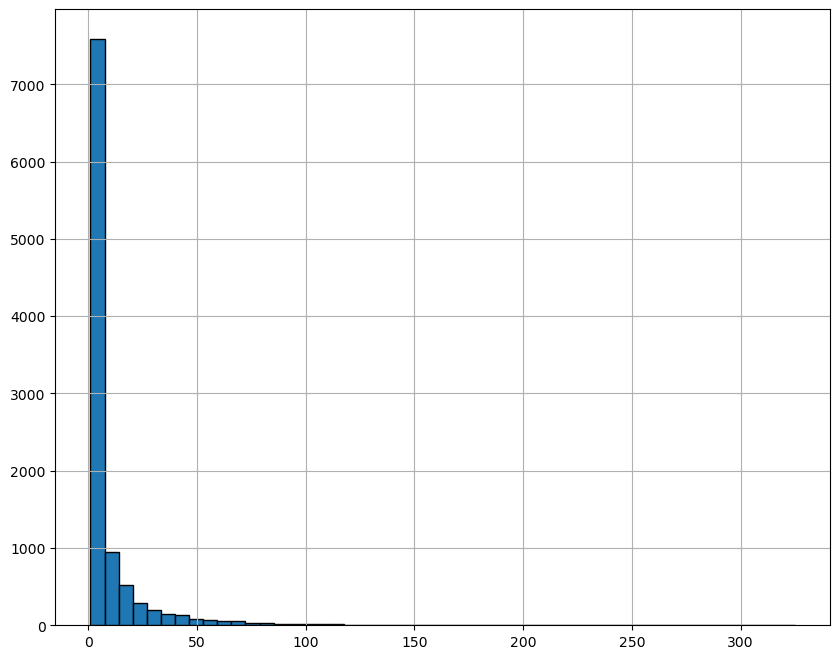

In [33]:
plt.figure(figsize=(10,8))
plt.rcParams['patch.force_edgecolor'] = True
cnt['count_rating'].hist(bins=50)
plt.show()

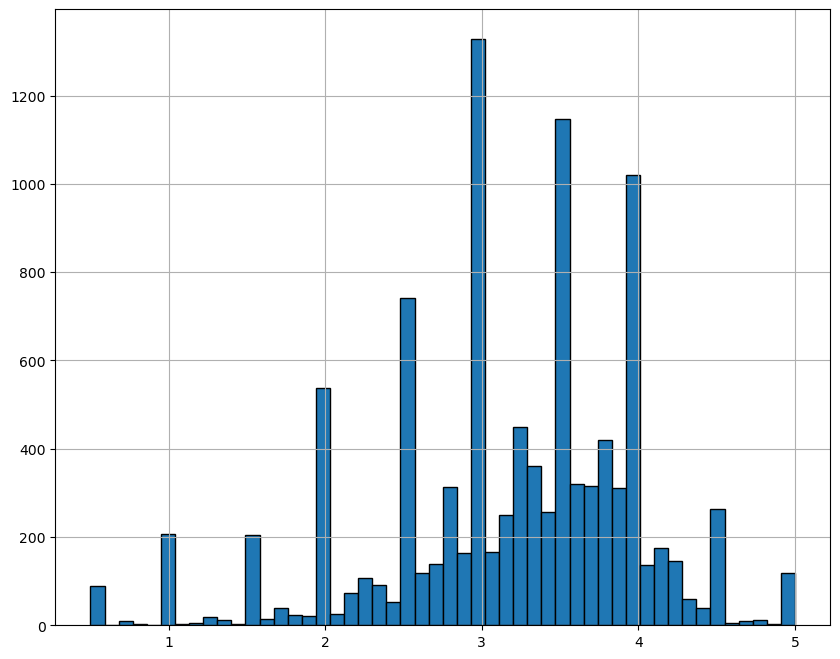

In [34]:
plt.figure(figsize=(10,8))
plt.rcParams['patch.force_edgecolor'] = True
avg['avg_rating'].hist(bins=50)
plt.show()

In [35]:
popularite=avg.merge(cnt,on='title')

In [36]:
popularite.head(10)

,title,avg_rating,count_rating
0,From One Second to the Next 2013,5.0,1
1,Topkapi 1964,5.0,1
2,Hush Hush Sweet Charlotte 1964,5.0,1
3,Young at Heart a k a Young Heart 2007,5.0,1
4,October Baby 2011,5.0,1
5,Safe Haven 2013,5.0,1
6,Time of the Gypsies Dom za vesanje 1989,5.0,1
7,Traviata La 1982,5.0,1
8,Hunchback of Notre Dame The Notre Dame de Pari...,5.0,1
9,Lawless Heart The 2003,5.0,1


Классическая формула IMDb / Bayesian Average для «взвешенного рейтинга». Применяется, чтобы фильмы с 1–2 оценками «5.0» не обгоняли фильмы с 1000 оценок «4.5»


V – количество оценок у конкретной фильма

R – средний рейтинг этой фильма

m – «порог доверия» — сколько оценок нужно, чтобы рейтинг считался надёжным

c - средний рейтинг по всем фильмам


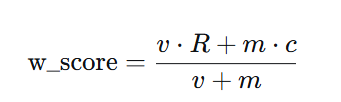

m — порог доверия. Здесь выбран как 90-й процентиль числа оценок: 90% фильмы имеют меньше оценок, чем m, и только топ-10% — больше.
Смысл: чтобы «обогнать» порог и получить рейтинг, близкий к своему настоящему R, книга должна набрать как минимум столько оценок, сколько набрали 90% лучших по популярностифильмаг. Это довольно строгий порог — он сильно тянет вниз рейтинги редкихфильмаг.


In [37]:
v = popularite["count_rating"]
R = popularite["avg_rating"]
m = v.quantile(0.90)
c = R.mean()
popularite['w_score']=((v*R) + (m*c)) / (v+m)

In [38]:
popularite["count_rating"].describe()

count    10323.000000
mean        10.204301
std         22.834557
min          1.000000
25%          1.000000
50%          3.000000
75%          8.000000
max        325.000000
Name: count_rating, dtype: float64

In [39]:
pop_sort=popularite.sort_values('w_score',ascending=False)

In [40]:
pop_sort

,title,avg_rating,count_rating,w_score
412,Shawshank Redemption The 1994,4.454545,308,4.358650
434,Godfather The 1972,4.392857,210,4.263534
482,Usual Suspects The 1995,4.328947,228,4.215141
501,Schindler s List 1993,4.296371,248,4.193885
516,Matrix The 1999,4.264368,261,4.169338
...,...,...,...,...
9133,Anaconda 1997,2.041667,36,2.507058
9711,Super Mario Bros 1993,1.807692,26,2.479031
9087,Wild Wild West 1999,2.164179,67,2.439463
9719,Speed 2 Cruise Control 1997,1.774194,31,2.400546


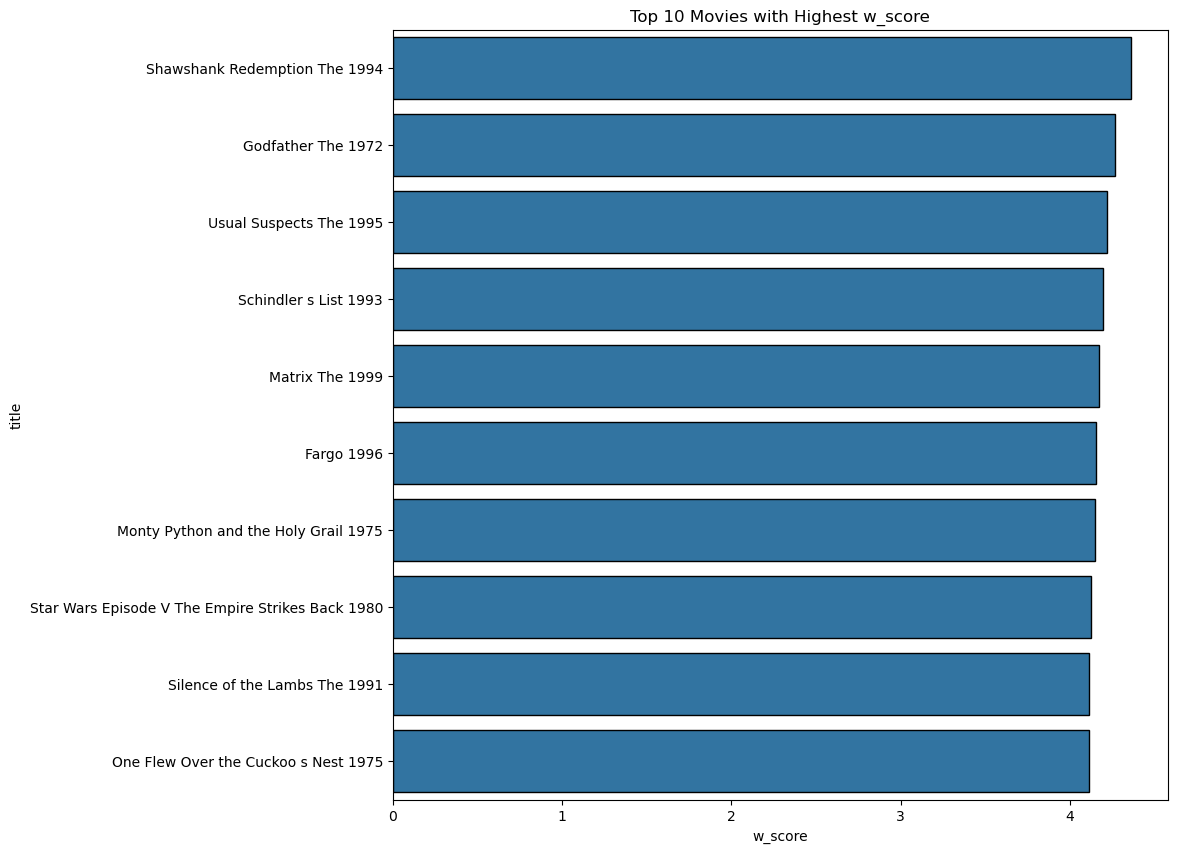

In [41]:
top_10_movies = pop_sort.head(10)

plt.figure(figsize=(10, 10))
sns.barplot(x='w_score', y='title', data=top_10_movies)
plt.xlabel('w_score')
plt.ylabel('title')
plt.title('Top 10 Movies with Highest w_score')
plt.show()

In [42]:
ratings_mean_count = pd.DataFrame(movie_data.groupby('title')['rating'].mean())

In [43]:
ratings_mean_count['rating_counts'] = pd.DataFrame(movie_data.groupby('title')['rating'].count())

In [44]:
ratings_mean_count.head()

,rating,rating_counts
title,,
'71 (2014),3.500,1
'Hellboy': The Seeds of Creation (2004),3.000,1
'Round Midnight (1986),2.500,1
'Til There Was You (1997),4.000,3
"'burbs, The (1989)",3.125,20


<Figure size 1000x800 with 0 Axes>

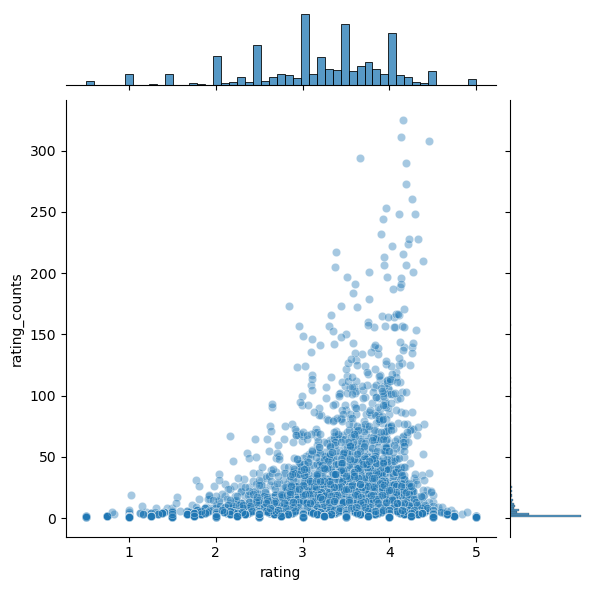

In [45]:
plt.figure(figsize=(10,8))
plt.rcParams['patch.force_edgecolor'] = True
sns.jointplot(x='rating', y='rating_counts', data=ratings_mean_count, alpha=0.4)
plt.show()

## **Cистема рекомендаций по коллаборативной фильтрации (с использованием корреляции)**

In [46]:
new_df=df[df['userId'].map(df['userId'].value_counts()) > 200]  

In [47]:
new_df

,userId,movieId,rating,timestamp,title
1640,22,3,2.5,1111573615,Grumpier Old Men 1995
1641,22,5,2.5,1111573645,Father of the Bride Part II 1995
1642,22,25,3.5,1111573597,Leaving Las Vegas 1995
1643,22,32,2.5,1111575931,Twelve Monkeys a k a 12 Monkeys 1995
1644,22,36,4.5,1111573574,Dead Man Walking 1995
...,...,...,...,...,...
105334,668,142488,4.0,1451535844,Spotlight 2015
105335,668,142507,3.5,1451535889,Pawn Sacrifice 2015
105336,668,143385,4.0,1446388585,Bridge of Spies 2015
105337,668,144976,2.5,1448656898,Bone Tomahawk 2015


In [48]:
users_pivot=new_df.pivot_table(index=["userId"],columns=["title"],values="rating")
users_pivot.fillna(0,inplace=True)

In [49]:
users_pivot.head()

title,10 000 BC 2008,10 1979,10 Items or Less 2006,10 Things I Hate About You 1999,10 to Midnight 1983,100 Girls 2000,101 Dalmatians 1996,101 Dalmatians One Hundred and One Dalmatians 1961,101 Reykjavik 101 Reykjavík 2000,102 Dalmatians 2000,...,Zulu 1964,a k a Tommy Chong 2005,batteries not included 1987,burbs The 1989,eXistenZ 1999,loudQUIETloud A Film About the Pixies 2006,night Mother 1986,xXx 2002,xXx State of the Union 2005,À nous la liberté Freedom for Us 1931
userId,,,,,,,,,,,,,,,,,,,,,
22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [50]:
forrest_gump_ratings = users_pivot['Forrest Gump 1994']

forrest_gump_ratings.head()

userId
22    5.0
24    0.0
29    4.0
32    5.0
38    4.5
Name: Forrest Gump 1994, dtype: float64

In [51]:
movies_like_forest_gump = users_pivot.corrwith(forrest_gump_ratings)

In [52]:
corr_forrest_gump = pd.DataFrame(movies_like_forest_gump, columns=['Correlation'])
corr_forrest_gump.dropna(inplace=True)
corr_forrest_gump.head()

,Correlation
title,
10 000 BC 2008,0.119974
10 1979,-0.009080
10 Items or Less 2006,0.073931
10 Things I Hate About You 1999,0.111775
10 to Midnight 1983,0.039566


In [53]:
corr_forrest_gump.sort_values('Correlation', ascending=False).head(10)

,Correlation
title,
Forrest Gump 1994,1.000000
Ace Ventura Pet Detective 1994,0.455346
Mrs Doubtfire 1993,0.454299
Back to the Future Part III 1990,0.403244
Dumb Dumber Dumb and Dumber 1994,0.399423
Green Mile The 1999,0.398384
Titanic 1997,0.381816
Good Will Hunting 1997,0.381489
Home Alone 1990,0.380563


In [54]:
def same_movies(movie):
    users_vote_film=users_pivot[movie]
    similar_with=users_pivot.corrwith(users_vote_film)
    similar_with = pd.DataFrame(similar_with, columns=['correlation'])
    print(similar_with)
    df=similar_with.sort_values('correlation',ascending=False).head(10)
    print(df)
    df_sort=df[df['correlation']>0.8]
    return df_sort

<img src="poster7.webp" style="width: 250px; height: 400px"></img>

In [55]:
same_movies('Forrest Gump 1994')

                                            correlation
title                                                  
10 000 BC 2008                                 0.119974
10 1979                                       -0.009080
10 Items or Less 2006                          0.073931
10 Things I Hate About You 1999                0.111775
10 to Midnight 1983                            0.039566
...                                                 ...
loudQUIETloud A Film About the Pixies 2006     0.016040
night Mother 1986                             -0.031011
xXx 2002                                       0.039279
xXx State of the Union 2005                    0.080305
À nous la liberté Freedom for Us 1931          0.039566

[9978 rows x 1 columns]
                                  correlation
title                                        
Forrest Gump 1994                    1.000000
Ace Ventura Pet Detective 1994       0.455346
Mrs Doubtfire 1993                   0.454299
Back to the Futur

,correlation
title,
Forrest Gump 1994,1.0


<img src="poster6.webp" style="width: 250px; height: 400px"></img>

In [56]:
same_movies('Ace Ventura Pet Detective 1994')

                                            correlation
title                                                  
10 000 BC 2008                                 0.184014
10 1979                                       -0.028667
10 Items or Less 2006                          0.021270
10 Things I Hate About You 1999                0.254868
10 to Midnight 1983                            0.123261
...                                                 ...
loudQUIETloud A Film About the Pixies 2006     0.072096
night Mother 1986                              0.072096
xXx 2002                                       0.147603
xXx State of the Union 2005                    0.269465
À nous la liberté Freedom for Us 1931         -0.081399

[9978 rows x 1 columns]
                                    correlation
title                                          
Ace Ventura Pet Detective 1994         1.000000
Ace Ventura When Nature Calls 1995     0.675153
Dumb Dumber Dumb and Dumber 1994       0.636552
Fifth E

,correlation
title,
Ace Ventura Pet Detective 1994,1.0


<img src="poster5.webp" style="width: 250px; height: 400px"></img>

In [57]:
same_movies('Ace Ventura When Nature Calls 1995')

                                            correlation
title                                                  
10 000 BC 2008                                 0.308647
10 1979                                       -0.050439
10 Items or Less 2006                          0.062305
10 Things I Hate About You 1999                0.181382
10 to Midnight 1983                            0.130315
...                                                 ...
loudQUIETloud A Film About the Pixies 2006     0.005666
night Mother 1986                              0.005666
xXx 2002                                       0.154902
xXx State of the Union 2005                    0.364710
À nous la liberté Freedom for Us 1931         -0.056659

[9978 rows x 1 columns]
                                                    correlation
title                                                          
Ace Ventura When Nature Calls 1995                     1.000000
Ace Ventura Pet Detective 1994                         

,correlation
title,
Ace Ventura When Nature Calls 1995,1.0


### **Коллаборативная фильтрация: модель NearestNeighbours из scikit-learn для системы рекомендаций**

In [58]:
df.head()

,userId,movieId,rating,timestamp,title
0,1,16,4.0,1217897793,Casino 1995
1,1,24,1.5,1217895807,Powder 1995
2,1,32,4.0,1217896246,Twelve Monkeys a k a 12 Monkeys 1995
3,1,47,4.0,1217896556,Seven a k a Se7en 1995
4,1,50,4.0,1217896523,Usual Suspects The 1995


In [59]:
users_pivot

title,10 000 BC 2008,10 1979,10 Items or Less 2006,10 Things I Hate About You 1999,10 to Midnight 1983,100 Girls 2000,101 Dalmatians 1996,101 Dalmatians One Hundred and One Dalmatians 1961,101 Reykjavik 101 Reykjavík 2000,102 Dalmatians 2000,...,Zulu 1964,a k a Tommy Chong 2005,batteries not included 1987,burbs The 1989,eXistenZ 1999,loudQUIETloud A Film About the Pixies 2006,night Mother 1986,xXx 2002,xXx State of the Union 2005,À nous la liberté Freedom for Us 1931
userId,,,,,,,,,,,,,,,,,,,,,
22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
650,0.0,0.0,0.0,5.0,0.0,0.0,0.0,5.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
659,0.0,0.0,0.0,2.5,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
665,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

# Подготовка данных и модели
movie_df_matrix = csr_matrix(users_pivot.values).T
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(movie_df_matrix)

def find_similar_movies(movie_title, num_neighbors=10, model=model_knn):
    movie_index = users_pivot.T.index.get_loc(movie_title)
    movie_vector = movie_df_matrix[movie_index]
    distances, indices = model.kneighbors(movie_vector, n_neighbors=num_neighbors+1)
    
    similar_indices = indices[0][1:]
    similar_distances = distances[0][1:]
    
    list_similar_movies = users_pivot.T.index[similar_indices].tolist()
    
    return pd.DataFrame({
        "Movie": list_similar_movies,
        "Distance": similar_distances
    })

<img src="poster4.webp"></img>

In [61]:
input_movie = '10 Items or Less 2006'
find_similar_movies(input_movie)

,Movie,Distance
0,Interview 2007,0.000000
1,Redbelt 2008,0.000000
2,Bottle Shock 2008,0.011233
3,W 2008,0.011233
4,Killshot 2008,0.017898
5,Women The 2008,0.051317
6,Nothing But the Truth 2008,0.105573
7,Fair Game 2010,0.161159
8,Messenger The 2009,0.185908
9,Confessions of a Shopaholic 2009,0.187017


<img src="poster3.webp"></img>

In [62]:
input_movie = '10 000 BC 2008'
find_similar_movies(input_movie)

,Movie,Distance
0,Ultraviolet 2006,0.073085
1,Domino 2005,0.227698
2,Fullmetal Alchemist The Sacred Star of Milos 2011,0.255792
3,Samsara 2011,0.255792
4,Fist of Fury Chinese Connection The Jing wu me...,0.255792
5,Jodorowsky s Dune 2013,0.255792
6,Batman Mr Freeze Subzero 1998,0.255792
7,Song of the Sea 2014,0.255792
8,Lords of Dogtown 2005,0.255792
9,Into the Woods 2014,0.255792


<img src="poster1.webp"></img>

In [63]:
input_movie = '10 to Midnight 1983'
find_similar_movies(input_movie)

,Movie,Distance
0,Woman Is a Woman A femme est une femme Une 1961,0.0
1,Dirty Carnival A Biyeolhan geori 2006,0.0
2,Diary of a Madman 1963,0.0
3,Justice League Throne of Atlantis 2015,0.0
4,Jesse Stone No Remorse 2010,0.0
5,Jesse Stone Sea Change 2007,0.0
6,Jesse Stone Stone Cold 2005,0.0
7,Jesse Stone Death in Paradise 2006,0.0
8,Jesse Stone Night Passage 2006,0.0
9,Corman s World Exploits of a Hollywood Rebel 2011,0.0


<img src="poster2.webp"></img>

In [64]:
input_movie = '101 Dalmatians One Hundred and One Dalmatians 1961'
find_similar_movies(input_movie)

,Movie,Distance
0,Peter Pan 1953,0.294193
1,Sleeping Beauty 1959,0.299976
2,Beauty and the Beast 1991,0.319744
3,Jungle Book The 1967,0.324542
4,Bambi 1942,0.338538
5,Dumbo 1941,0.356204
6,Anastasia 1997,0.356882
7,Little Mermaid The 1989,0.370263
8,Cinderella 1950,0.380532
9,Snow White and the Seven Dwarfs 1937,0.385268


Что происходит с любимым фильмом? Да, это совпадает, но только малобюджетный фильм Terminator

In [107]:
input_movie = 'Terminator 2 Judgment Day 1991'
find_similar_movies(input_movie)

,Movie,Distance
0,Terminator The 1984,0.094333
1,Die Hard 1988,0.123366
2,Raiders of the Lost Ark Indiana Jones and the ...,0.134267
3,Star Wars Episode V The Empire Strikes Back 1980,0.143958
4,Back to the Future 1985,0.148441
5,Braveheart 1995,0.149311
6,Star Wars Episode VI Return of the Jedi 1983,0.152472
7,Jurassic Park 1993,0.157391
8,Fugitive The 1993,0.159946
9,Star Wars Episode IV A New Hope 1977,0.164688


In [108]:
input_movie = 'Terminator The 1984'
find_similar_movies(input_movie)

,Movie,Distance
0,Terminator 2 Judgment Day 1991,0.094333
1,Die Hard 1988,0.120405
2,Raiders of the Lost Ark Indiana Jones and the ...,0.135079
3,Blade Runner 1982,0.158149
4,Alien 1979,0.164528
5,Star Wars Episode IV A New Hope 1977,0.164837
6,Star Wars Episode V The Empire Strikes Back 1980,0.165094
7,Silence of the Lambs The 1991,0.168959
8,Fugitive The 1993,0.169449
9,Jurassic Park 1993,0.169473


Терминатор и Терминатор 2 - это золотые шедевры, которые я видел!

In [109]:
input_movie = 'Terminator 3 Rise of the Machines 2003'
find_similar_movies(input_movie)

,Movie,Distance
0,Matrix Revolutions The 2003,0.246640
1,Bad Santa 2003,0.301249
2,X2 X Men United 2003,0.305269
3,Hulk 2003,0.309448
4,Kill Bill Vol 1 2003,0.323653
5,Predator 1987,0.340428
6,Hellboy 2004,0.344410
7,Spider Man 2002,0.346592
8,Chronicles of Riddick The 2004,0.348377
9,Pirates of the Caribbean The Curse of the Blac...,0.357068


In [110]:
input_movie = 'Spider Man 2002'
find_similar_movies(input_movie)

,Movie,Distance
0,Minority Report 2002,0.192851
1,Lord of the Rings The Fellowship of the Ring T...,0.229673
2,X Men 2000,0.230518
3,Shrek 2001,0.231427
4,Ocean s Eleven 2001,0.241036
5,Monsters Inc 2001,0.242948
6,Lord of the Rings The Two Towers The 2002,0.245469
7,Memento 2000,0.254926
8,Matrix The 1999,0.262794
9,Spider Man 2 2004,0.262836


In [111]:
input_movie = 'Spider Man 2 2004'
find_similar_movies(input_movie)

,Movie,Distance
0,Incredibles The 2004,0.249251
1,Batman Begins 2005,0.256951
2,Spider Man 2002,0.262836
3,X2 X Men United 2003,0.266468
4,Lord of the Rings The Return of the King The 2003,0.321249
5,Sin City 2005,0.324775
6,Ocean s Eleven 2001,0.329053
7,Matrix The 1999,0.330336
8,Minority Report 2002,0.330848
9,Kill Bill Vol 2 2004,0.331817


In [112]:
input_movie = 'Shrek 2001'
find_similar_movies(input_movie)

,Movie,Distance
0,Monsters Inc 2001,0.165775
1,Lord of the Rings The Fellowship of the Ring T...,0.188703
2,Spider Man 2002,0.231427
3,Lord of the Rings The Two Towers The 2002,0.246425
4,Minority Report 2002,0.249519
5,Finding Nemo 2003,0.254116
6,Toy Story 1995,0.258329
7,Sixth Sense The 1999,0.263775
8,Toy Story 2 1999,0.269210
9,Gladiator 2000,0.274692


In [65]:
users_pivot

title,10 000 BC 2008,10 1979,10 Items or Less 2006,10 Things I Hate About You 1999,10 to Midnight 1983,100 Girls 2000,101 Dalmatians 1996,101 Dalmatians One Hundred and One Dalmatians 1961,101 Reykjavik 101 Reykjavík 2000,102 Dalmatians 2000,...,Zulu 1964,a k a Tommy Chong 2005,batteries not included 1987,burbs The 1989,eXistenZ 1999,loudQUIETloud A Film About the Pixies 2006,night Mother 1986,xXx 2002,xXx State of the Union 2005,À nous la liberté Freedom for Us 1931
userId,,,,,,,,,,,,,,,,,,,,,
22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
650,0.0,0.0,0.0,5.0,0.0,0.0,0.0,5.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
659,0.0,0.0,0.0,2.5,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
665,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [66]:
def find_favorite_movies(User_id, num_movies=10):
    user_ratings = users_pivot.loc[User_id]    
    top_movies = user_ratings.sort_values(ascending=False).head(num_movies)    
    return pd.DataFrame({
        "favorite movies": top_movies.index,
        "rating": top_movies.values
    })

In [67]:
User_id= 22 
find_favorite_movies(User_id)

,favorite movies,rating
0,Forrest Gump 1994,5.0
1,Army of Darkness 1993,5.0
2,What Lies Beneath 2000,5.0
3,Snatch 2000,5.0
4,Ice Age 2002,5.0
5,K PAX 2001,5.0
6,Beautiful Mind A 2001,5.0
7,Fear and Loathing in Las Vegas 1998,5.0
8,Royal Tenenbaums The 2001,5.0
9,Catch Me If You Can 2002,5.0


In [68]:
User_id= 668 
find_favorite_movies(User_id)

,favorite movies,rating
0,Gentlemen Prefer Blondes 1953,5.0
1,Black Swan 2010,5.0
2,Slumdog Millionaire 2008,5.0
3,Rome Open City a k a Open City Roma città aper...,5.0
4,Rififi Du rififi chez les hommes 1955,5.0
5,Wizard of Oz The 1939,5.0
6,Ran 1985,5.0
7,50 Children The Rescue Mission of Mr And Mrs K...,5.0
8,Psycho 1960,5.0
9,Cabaret 1972,5.0


In [69]:
User_id= 38 
find_favorite_movies(User_id)

,favorite movies,rating
0,Dr Horrible s Sing Along Blog 2008,5.0
1,Monsters Inc 2001,5.0
2,Beautiful Mind A 2001,5.0
3,Toy Story 1995,5.0
4,Up 2009,5.0
5,Dark Knight The 2008,5.0
6,Batman 1966,5.0
7,Inception 2010,5.0
8,Robin Hood Men in Tights 1993,5.0
9,Princess Bride The 1987,5.0


In [70]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

user_item_matrix = csr_matrix(users_pivot.values)
model_user_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_user_knn.fit(user_item_matrix)


def find_user_recommendations(User_id, num_neighbors=20, num_movies=10):
    user_index = users_pivot.index.get_loc(User_id)
    
    # 1. Ищем похожих пользователей
    distances, indices = model_user_knn.kneighbors(
        user_item_matrix[user_index],
        n_neighbors=num_neighbors + 1
    )
    similar_user_indices = indices[0][1:]
    similar_distances   = distances[0][1:]
    
    # 2. Оценки похожих пользователей (DataFrame: users × movies)
    similar_ratings = users_pivot.iloc[similar_user_indices]
    
    # 3. Взвешенное среднее: чем ближе пользователь (меньше distance), тем больше вес
    weights = 1 / (similar_distances + 1e-9)          # избегаем деления на 0
    weighted_scores = similar_ratings.T.dot(weights) / weights.sum()
    
    # 4. Исключаем фильма, которые целевой пользователь уже оценил (> 0)
    target_ratings = users_pivot.iloc[user_index]
    unread = target_ratings[target_ratings == 0].index
    candidates = weighted_scores.loc[unread]
    
    # 5. Топ-N по взвешенной оценке
    top_movies = candidates.sort_values(ascending=False).head(num_movies)
    
    return pd.DataFrame({
        "Recommended Movies": top_movies.index,
        "Score": top_movies.values.round(3)
    })

In [71]:
User_id= 22  
find_user_recommendations(User_id)

,Recommended Movies,Score
0,Lord of the Rings The Fellowship of the Ring T...,4.250
1,American Beauty 1999,3.981
2,Shawshank Redemption The 1994,3.948
3,Matrix The 1999,3.907
4,Star Wars Episode VI Return of the Jedi 1983,3.784
5,Raiders of the Lost Ark Indiana Jones and the ...,3.780
6,Groundhog Day 1993,3.777
7,Star Wars Episode IV A New Hope 1977,3.731
8,Fifth Element The 1997,3.705
9,Back to the Future 1985,3.656


In [72]:
User_id= 38  
find_user_recommendations(User_id)

,Recommended Movies,Score
0,Fight Club 1999,3.957
1,American Beauty 1999,3.657
2,Gladiator 2000,3.388
3,Groundhog Day 1993,3.377
4,Seven a k a Se7en 1995,3.291
5,Die Hard 1988,3.223
6,Eternal Sunshine of the Spotless Mind 2004,3.036
7,Fugitive The 1993,2.990
8,Fifth Element The 1997,2.955
9,Minority Report 2002,2.948


In [73]:
User_id= 668  
find_user_recommendations(User_id)

,Recommended Movies,Score
0,RoboCop 1987,3.121
1,Mask The 1994,2.962
2,Back to the Future Part III 1990,2.918
3,Ace Ventura Pet Detective 1994,2.901
4,Chasing Amy 1997,2.865
5,Nightmare Before Christmas The 1993,2.745
6,Dogma 1999,2.724
7,Wedding Singer The 1998,2.637
8,Dumb Dumber Dumb and Dumber 1994,2.625
9,This Is Spinal Tap 1984,2.584


**Косинусное сходство**

In [74]:
users_pivot.head()

title,10 000 BC 2008,10 1979,10 Items or Less 2006,10 Things I Hate About You 1999,10 to Midnight 1983,100 Girls 2000,101 Dalmatians 1996,101 Dalmatians One Hundred and One Dalmatians 1961,101 Reykjavik 101 Reykjavík 2000,102 Dalmatians 2000,...,Zulu 1964,a k a Tommy Chong 2005,batteries not included 1987,burbs The 1989,eXistenZ 1999,loudQUIETloud A Film About the Pixies 2006,night Mother 1986,xXx 2002,xXx State of the Union 2005,À nous la liberté Freedom for Us 1931
userId,,,,,,,,,,,,,,,,,,,,,
22,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
29,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
32,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0
38,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [75]:
from sklearn.metrics.pairwise import cosine_similarity 

In [76]:
similarity_score = cosine_similarity(users_pivot.T)

In [77]:
similarity_score.shape

(9978, 9978)

In [78]:
similarity_score

array([[1.        , 0.        , 0.        , ..., 0.19223226, 0.42966892,
        0.        ],
       [0.        , 1.        , 0.44280744, ..., 0.39167999, 0.        ,
        0.68041382],
       [0.        , 0.44280744, 1.        , ..., 0.30258403, 0.146119  ,
        0.65079137],
       ...,
       [0.19223226, 0.39167999, 0.30258403, ..., 1.        , 0.39200433,
        0.30996521],
       [0.42966892, 0.        , 0.146119  , ..., 0.39200433, 1.        ,
        0.        ],
       [0.        , 0.68041382, 0.65079137, ..., 0.30996521, 0.        ,
        1.        ]], shape=(9978, 9978))

In [79]:
users_pivot2 = users_pivot.T

In [80]:
users_pivot2

userId,22,24,29,32,38,44,54,60,62,63,...,607,615,622,627,628,650,659,665,666,668
title,,,,,,,,,,,,,,,,,,,,,
10 000 BC 2008,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10 1979,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5
10 Items or Less 2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0
10 Things I Hate About You 1999,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0,2.0,1.5,...,3.0,0.0,0.0,3.5,0.0,5.0,2.5,0.0,4.0,2.0
10 to Midnight 1983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
loudQUIETloud A Film About the Pixies 2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
night Mother 1986,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
xXx 2002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.5,1.5,...,0.0,0.0,4.0,2.5,0.0,0.0,0.0,0.0,0.0,3.5


In [81]:
def recommend(movies_name):
    if movies_name not in users_pivot2.index:
        return f"Фильм '{movies_name}' не найден в базе рекомендаций."
    
    index = np.where(users_pivot2.index == movies_name)[0][0]
    
    similar_movies = sorted(list(enumerate(similarity_score[index])), key=lambda x: x[1], reverse=True)[1:11]
    
    data = []
    
    for i in similar_movies:
        movie_title = users_pivot2.index[i[0]]
        score = i[1]
        
        temp_df = movies[movies['title'] == movie_title]
        
        if not temp_df.empty:
            
            data.append({
                "Title": movie_title,
                "Similarity Score": score
            })

    return pd.DataFrame(data)

In [82]:
recommend("10 000 BC 2008")

""


In [83]:
recommend("10 to Midnight 1983")

""


In [84]:
recommend("1984")

"Фильм '1984' не найден в базе рекомендаций."

In [85]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

# Матрица user-item уже есть: users_pivot (User-ID × title)
# Преобразуем в разреженную матрицу — это ускорит KNN и сэкономит память
users_sparse = csr_matrix(users_pivot.values)

# Обучаем модель ближайших соседей по пользователям
# metric='cosine' — стандарт для коллаборативной фильтрации
# algorithm='brute' — т.к. матрица разреженная
user_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=11)
user_knn.fit(users_sparse)

print("Модель обучена. Форма матрицы:", users_sparse.shape)

Модель обучена. Форма матрицы: (132, 9978)


In [86]:
def recommend_for_user(user_id, n_recommendations=10):
    """
    Рекомендует фильмы пользователю на основе оценок похожих пользователей.
    """
    if user_id not in users_pivot.index:
        return f"Пользователь {user_id} отсутствует в обучающей выборке."

    # Индекс пользователя в матрице
    user_idx = users_pivot.index.get_loc(user_id)
    user_vector = users_sparse[user_idx]

    # Находим n_neighbors+1 ближайших (первый — сам пользователь)
    distances, indices = user_knn.kneighbors(user_vector, n_neighbors=11)

    distances = distances.flatten()
    indices = indices.flatten()

    # Исключаем самого пользователя
    similar_users = indices[1:]
    similarities = 1 - distances[1:]  # cosine distance → similarity

    # Собираем оценки похожих пользователей
    similar_users_ratings = users_pivot.iloc[similar_users]

    # Взвешенное среднее по схожести
    weighted_ratings = similar_users_ratings.T.dot(similarities) / similarities.sum()
    weighted_ratings = pd.Series(weighted_ratings, index=users_pivot.columns)

    # Убираем фильмы, которые пользователь уже смотрел
    already_read = users_pivot.loc[user_id]
    already_read = already_read[already_read > 0].index
    weighted_ratings = weighted_ratings.drop(already_read, errors='ignore')

    # Топ-N
    top_recs = weighted_ratings.sort_values(ascending=False).head(n_recommendations)
    return top_recs

# Пример
user_example = users_pivot.index[0]
recommendations = recommend_for_user(user_example, n_recommendations=10)
print(f"\nТоп-10 рекомендаций для пользователя {user_example}:\n")
print(recommendations)


Топ-10 рекомендаций для пользователя 22:

title
Lord of the Rings The Fellowship of the Ring The 2001                         4.159070
Matrix The 1999                                                               4.116147
American Beauty 1999                                                          4.066561
Silence of the Lambs The 1991                                                 4.021741
Raiders of the Lost Ark Indiana Jones and the Raiders of the Lost Ark 1981    4.009777
Star Wars Episode VI Return of the Jedi 1983                                  3.961368
Stand by Me 1986                                                              3.955536
Die Hard 1988                                                                 3.911460
Fifth Element The 1997                                                        3.865431
Pirates of the Caribbean The Curse of the Black Pearl 2003                    3.864633
dtype: float64


In [87]:
user_example = users_pivot.index[1]
recommendations = recommend_for_user(user_example, n_recommendations=10)
print(f"\nТоп-10 рекомендаций для пользователя {user_example}:\n")
print(recommendations)


Топ-10 рекомендаций для пользователя 24:

title
Wizard of Oz The 1939                               4.686052
One Flew Over the Cuckoo s Nest 1975                4.618921
Lawrence of Arabia 1962                             4.248344
Fargo 1996                                          3.897974
Streetcar Named Desire A 1951                       3.854810
Annie Hall 1977                                     3.786982
Singin in the Rain 1952                             3.557563
Blade Runner 1982                                   3.521380
Star Wars Episode V The Empire Strikes Back 1980    3.331461
Saving Private Ryan 1998                            3.290394
dtype: float64


In [98]:
# Транспонируем: фильмы × пользователи
movie_pivot = users_pivot.T
movie_sparse = csr_matrix(movie_pivot.values)

movie_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=11)
movie_knn.fit(movie_sparse)

def similar_movies(movie_title, n=10):
    """Возвращает n наиболее похожих фильмов."""
    if movie_title not in movie_pivot.index:
        return f"Фильм '{movie_title}' отсутствует в базе."

    movie_idx = movie_pivot.index.get_loc(movie_title)
    movie_vector = movie_sparse[movie_idx]

    distances, indices = movie_knn.kneighbors(movie_vector, n_neighbors=n + 1)
    distances = distances.flatten()[1:]
    indices = indices.flatten()[1:]

    result = pd.DataFrame({
        'Title': movie_pivot.index[indices],
        'Similarity': 1 - distances
    }).reset_index(drop=True)

    return result

# Пример: похожие книги на "Wizard of Oz The"
print("\nПохожие фильмы на 'Wizard of Oz The':\n")
print(similar_movies('Wizard of Oz The 1939', n=10))


Похожие фильмы на 'Wizard of Oz The':

                                               Title  Similarity
0                                    Casablanca 1942    0.702640
1                                      Fantasia 1940    0.700149
2                     E T the Extra Terrestrial 1982    0.697409
3               Star Wars Episode IV A New Hope 1977    0.673711
4   Star Wars Episode V The Empire Strikes Back 1980    0.670097
5                      Silence of the Lambs The 1991    0.664213
6  Raiders of the Lost Ark Indiana Jones and the ...    0.661137
7                                        Psycho 1960    0.650352
8                            M A S H a k a MASH 1970    0.649213
9                                          Babe 1995    0.647114


<img src="poster8.webp" style="width: 250px; height: 400px"></img>

<img src="poster9.webp" style="width: 250px; height: 400px"></img>

<img src="poster10.webp" style="width: 250px; height: 400px"></img>

In [89]:
print("\nПохожие фильмы на 'E T the Extra Terrestrial':\n")
print(similar_books('E T the Extra Terrestrial 1982', n=10))


Похожие фильмы на 'E T the Extra Terrestrial':

                                               Title  Similarity
0  Raiders of the Lost Ark Indiana Jones and the ...    0.826817
1       Star Wars Episode VI Return of the Jedi 1983    0.813742
2   Star Wars Episode V The Empire Strikes Back 1980    0.812174
3                            Back to the Future 1985    0.802901
4                                 Jurassic Park 1993    0.800477
5                                     Toy Story 1995    0.792055
6               Star Wars Episode IV A New Hope 1977    0.787039
7                                 Groundhog Day 1993    0.784392
8                      Silence of the Lambs The 1991    0.777553
9            Indiana Jones and the Last Crusade 1989    0.771977


<img src="poster11.webp" style="width: 250px; height: 400px"></img>
<a href="https://ru.wikipedia.org/wiki/E.T._the_Extra-Terrestrial">E.T the Extra Terrestrial знакомы, как видеоигра, которая потерпит крах империи Atari, начинает кризис видеоигр</a>
<img src="game-easter-gg.webp" style="width: 550px; height: 250px"></img>

In [90]:
def hybrid_recommend(user_id=None, liked_movie=None,
                     n=10, alpha=0.4, beta=0.3, gamma=0.3):
    """
    Гибридные рекомендации.
    alpha — вес популярности,
    beta  — вес схожести с liked_book,
    gamma — вес user-based коллаборативной фильтрации.
    """
    scores = pd.Series(dtype=float)

    # 1. Популярность
    if alpha > 0:
        pop = pop_sort.set_index('title')['w_score']
        # Нормируем в [0, 1]
        pop_norm = (pop - pop.min()) / (pop.max() - pop.min())
        scores = scores.add(pop_norm * alpha, fill_value=0)

    # 2. Схожесть с liked_book
    if liked_movie is not None and beta > 0:
        sim = similar_books(liked_movie, n=200)
        if isinstance(sim, pd.DataFrame):
            sim_scores = sim.set_index('title')['Similarity']
            scores = scores.add(sim_scores * beta, fill_value=0)

    # 3. User-based CF
    if user_id is not None and gamma > 0:
        user_recs = recommend_for_user(user_id, n_recommendations=200)
        if isinstance(user_recs, pd.Series) and len(user_recs) > 0:
            user_norm = (user_recs - user_recs.min()) / \
                        (user_recs.max() - user_recs.min() + 1e-9)
            scores = scores.add(user_norm * gamma, fill_value=0)

    # Исключаем уже прочитанное
    if user_id is not None and user_id in users_pivot.index:
        read = users_pivot.loc[user_id]
        read = read[read > 0].index
        scores = scores.drop(read, errors='ignore')

    return scores.sort_values(ascending=False).head(n)

# Пример гибрида
print("\nГибридные рекомендации:\n")
print(hybrid_recommend(user_id=user_example, liked_movie='E T the Extra Terrestrial', n=10))


Гибридные рекомендации:

title
One Flew Over the Cuckoo s Nest 1975                0.647010
Wizard of Oz The 1939                               0.617285
Fargo 1996                                          0.592363
Lawrence of Arabia 1962                             0.570616
Annie Hall 1977                                     0.540922
Star Wars Episode V The Empire Strikes Back 1980    0.538490
Blade Runner 1982                                   0.537567
Streetcar Named Desire A 1951                       0.510061
Saving Private Ryan 1998                            0.499260
Singin in the Rain 1952                             0.495883
dtype: float64


In [91]:
print("\nГибридные рекомендации:\n")
print(hybrid_recommend(user_id=38, liked_movie='Singin in the Rain', n=10))


Гибридные рекомендации:

title
Fight Club 1999                               0.647075
Eternal Sunshine of the Spotless Mind 2004    0.550386
Groundhog Day 1993                            0.549921
Seven a k a Se7en 1995                        0.544172
Die Hard 1988                                 0.543421
Schindler s List 1993                         0.538109
American Beauty 1999                          0.533425
Office Space 1999                             0.529396
Gladiator 2000                                0.521490
Ghostbusters a k a Ghost Busters 1984         0.510926
dtype: float64


In [92]:
print("\nГибридные рекомендации:\n")
print(hybrid_recommend(user_id=32, liked_movie='Ghostbusters', n=10))


Гибридные рекомендации:

title
Vertigo 1958                            0.608166
Lawrence of Arabia 1962                 0.555369
Shawshank Redemption The 1994           0.546997
Pulp Fiction 1994                       0.536174
Saving Private Ryan 1998                0.535998
Monty Python and the Holy Grail 1975    0.525187
Alien 1979                              0.520747
Goodfellas 1990                         0.500216
It s a Wonderful Life 1946              0.491913
Reservoir Dogs 1992                     0.486371
dtype: float64


In [93]:
def train_test_split_interactions(df, test_size=0.2, random_state=42):
    """Разбивает взаимодействия 'пользователь-фильм' на train/test."""
    np.random.seed(random_state)
    mask = np.random.rand(len(df)) < (1 - test_size)
    return df[mask], df[~mask]

train_df, test_df = train_test_split_interactions(new_df)
print(f"Train: {len(train_df)}, Test: {len(test_df)}")

# Pivot только на train — чтобы избежать утечки данных
train_pivot = train_df.pivot_table(
    index='userId', columns='title', values='rating'
).fillna(0)

# Обучаем KNN на train
train_sparse = csr_matrix(train_pivot.values)
knn_eval = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=11)
knn_eval.fit(train_sparse)

def precision_recall_at_k(test_df, train_pivot, knn_model, k=10, threshold=6):
    precisions, recalls = [], []
    users = test_df['userId'].unique()

    for user in users:
        if user not in train_pivot.index:
            continue

        # Релевантные фильмы в тесте (высокая оценка)
        relevant = test_df[(test_df['userId'] == user) &
                           (test_df['rating'] >= threshold)]['title'].tolist()
        if not relevant:
            continue

        user_idx = train_pivot.index.get_loc(user)
        user_vec = train_sparse[user_idx]
        distances, indices = knn_model.kneighbors(user_vec, n_neighbors=11)

        # Усредняем оценки соседей
        neigh = indices.flatten()[1:]
        neigh_ratings = train_pivot.iloc[neigh].T.dot(1 - distances.flatten()[1:])
        neigh_ratings = pd.Series(neigh_ratings, index=train_pivot.columns)

        # Исключаем уже прочитанное
        read = train_pivot.loc[user]
        read = read[read > 0].index
        neigh_ratings = neigh_ratings.drop(read, errors='ignore')

        top_k = neigh_ratings.sort_values(ascending=False).head(k).index.tolist()

        hits = len(set(top_k) & set(relevant))
        precisions.append(hits / k)
        recalls.append(hits / len(relevant))

    return np.mean(precisions), np.mean(recalls)

prec, rec = precision_recall_at_k(test_df, train_pivot, knn_eval, k=10)
print(f"\nPrecision@10: {prec:.4f}")
print(f"Recall@10:    {rec:.4f}")

Train: 54992, Test: 13654

Precision@10: nan
Recall@10:    nan


D:\Anaconda\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
D:\Anaconda\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [94]:
import pickle
import os

os.makedirs('model_artifacts', exist_ok=True)

# Сохраняем всё нужное для инференса
artifacts = {
    'user_knn': user_knn,
    'movie_knn': movie_knn,
    'users_pivot': users_pivot,
    'movie_pivot': movie_pivot,
    'users_sparse': users_sparse,
    'movie_sparse': movie_sparse,
    'popularity': pop_sort,
}

with open('model_artifacts/recommender.pkl', 'wb') as f:
    pickle.dump(artifacts, f, protocol=pickle.HIGHEST_PROTOCOL)

print("Модель сохранена в model_artifacts/recommender.pkl")
print("Размер файла:", round(os.path.getsize('model_artifacts/recommender.pkl') / 1e6, 2), "МБ")

Модель сохранена в model_artifacts/recommender.pkl
Размер файла: 25.15 МБ


In [95]:
# Загрузка
with open('model_artifacts/recommender.pkl', 'rb') as f:
    loaded = pickle.load(f)

print("Модель загружена. Доступные ключи:", list(loaded.keys()))

# Быстрая проверка
sample_user = loaded['users_pivot'].index[0]
print(f"\nПример работы восстановленной модели для User-ID={sample_user}:")
print(loaded['popularity'].head(5)[['title', 'w_score']])

Модель загружена. Доступные ключи: ['user_knn', 'movie_knn', 'users_pivot', 'movie_pivot', 'users_sparse', 'movie_sparse', 'popularity']

Пример работы восстановленной модели для User-ID=22:
                             title   w_score
412  Shawshank Redemption The 1994  4.358650
434             Godfather The 1972  4.263534
482        Usual Suspects The 1995  4.215141
501          Schindler s List 1993  4.193885
516                Matrix The 1999  4.169338


In [96]:
sample_user = loaded['users_pivot'].index[3]
print(f"\nПример работы восстановленной модели для User-ID={sample_user}:")
print(loaded['popularity'].head(5)[['title', 'w_score']])


Пример работы восстановленной модели для User-ID=32:
                             title   w_score
412  Shawshank Redemption The 1994  4.358650
434             Godfather The 1972  4.263534
482        Usual Suspects The 1995  4.215141
501          Schindler s List 1993  4.193885
516                Matrix The 1999  4.169338


In [97]:
sample_user = loaded['users_pivot'].index[5]
print(f"\nПример работы восстановленной модели для User-ID={sample_user}:")
print(loaded['popularity'].head(5)[['title', 'w_score']])


Пример работы восстановленной модели для User-ID=44:
                             title   w_score
412  Shawshank Redemption The 1994  4.358650
434             Godfather The 1972  4.263534
482        Usual Suspects The 1995  4.215141
501          Schindler s List 1993  4.193885
516                Matrix The 1999  4.169338
